In [22]:
import tensorflow as tf
from tensorflow import keras 
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np

In [23]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

In [24]:
X_train.shape

(60000, 28, 28)

In [25]:
X_train = X_train / 255
X_test = X_test / 255

In [26]:
X_train_flattened = X_train.reshape(len(X_train),28*28)
X_test_flattened = X_test.reshape(len(X_test), 28 * 28)
X_train_flattened.shape

(60000, 784)

In [27]:
X_train_flattened[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [28]:
model = keras.Sequential([
    keras.layers.Dense(10, input_shape=(784,), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics =['accuracy']
)

model.fit(X_train_flattened, y_train, epochs=5)

c:\Users\boogey\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8779 - loss: 0.4709
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9158 - loss: 0.3037
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - accuracy: 0.9206 - loss: 0.2833
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9242 - loss: 0.2728
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9255 - loss: 0.2666


In [29]:
model.evaluate(X_test_flattened,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9255 - loss: 0.2664


[0.2663923501968384, 0.9254999756813049]

In [30]:
prediction = model.predict(X_test_flattened[0:1])
predicted_digit = np.argmax(prediction[0])

print("Predicted digit:", predicted_digit)
print("Actual digit:", y_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
Predicted digit: 7
Actual digit: 7


In [31]:
prediction = model.predict(X_test_flattened)
prediction_labels = [np.argmax(i) for i in prediction]
prediction_labels[:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4)]

In [32]:
cm =  tf.math.confusion_matrix(labels=y_test, predictions= prediction_labels)
cm

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 956,    0,    1,    2,    0,    5,   11,    2,    3,    0],
       [   0, 1110,    3,    2,    0,    1,    4,    2,   13,    0],
       [   4,    9,  921,   18,    7,    5,   13,    9,   41,    5],
       [   1,    0,   14,  930,    0,   19,    2,   10,   25,    9],
       [   1,    1,    3,    2,  901,    0,   12,    4,   10,   48],
       [   7,    2,    2,   38,    6,  773,   16,    6,   35,    7],
       [   8,    3,    6,    1,    7,   12,  916,    2,    3,    0],
       [   1,    5,   22,    8,    5,    1,    0,  938,    4,   44],
       [   4,    7,    6,   22,    9,   18,   10,   11,  876,   11],
       [   9,    7,    1,   10,   18,    6,    0,   15,    9,  934]],
      dtype=int32)>

Text(95.83333333333333, 0.5, 'Truth')

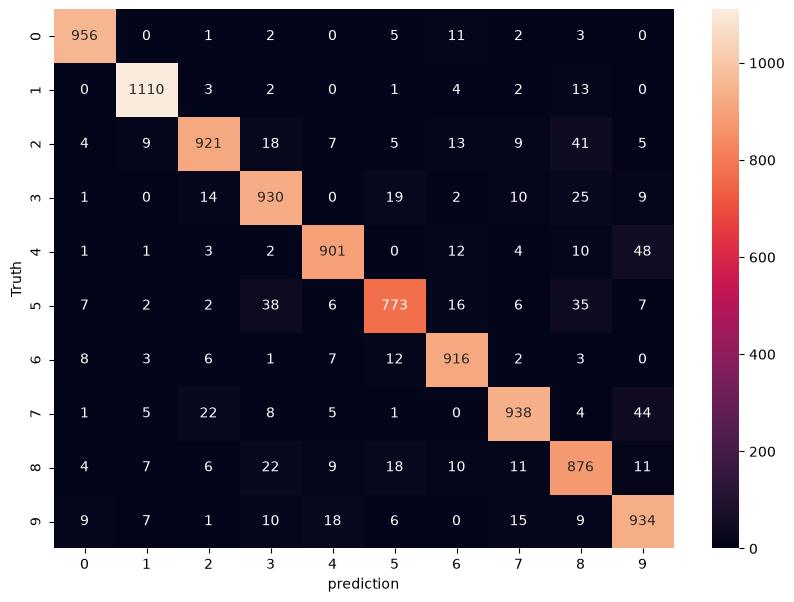

In [33]:
import seaborn as sn
plt.figure(figsize=(10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('prediction')
plt.ylabel('Truth')

In [34]:
%pip install tensorboard

Note: you may need to restart the kernel to use updated packages.


In [35]:
model = keras.Sequential([
    keras.layers.Dense(100, input_shape=(784,), activation = 'relu'),
    keras.layers.Dense(10, activation = 'sigmoid')
])

tb_callback = tf.keras.callbacks.TensorBoard(log_dir='logs', histogram_freq=1)

model.compile(
    optimizer='SGD',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train_flattened, y_train, epochs=5, callbacks=[tb_callback])

c:\Users\boogey\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.8374 - loss: 0.6461
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9046 - loss: 0.3403
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9176 - loss: 0.2927
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9262 - loss: 0.2632
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 4ms/step - accuracy: 0.9327 - loss: 0.2412


In [36]:
import os
import sysconfig
from pathlib import Path

tensorboard_executable = Path(sysconfig.get_path("scripts")) / (
    "tensorboard.exe" if os.name == "nt" else "tensorboard"
)
if not tensorboard_executable.is_file():
    raise FileNotFoundError(
        f"TensorBoard executable not found at {tensorboard_executable}. "
        "Run `%pip install tensorboard` in this notebook and restart the kernel."
    )
os.environ["TENSORBOARD_BINARY"] = str(tensorboard_executable)

%load_ext tensorboard
%tensorboard --logdir logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 12660), started 0:06:28 ago. (Use '!kill 12660' to kill it.)